In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../dataset/APL_Logistics_feature_engineered.csv",
    encoding="latin1"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (180519, 22)


,Type,Days for shipment (scheduled),Late_delivery_risk,Category Name,Customer Segment,Department Name,Latitude,Longitude,Market,Order City,...,Order Item Discount Rate,Order Item Product Price,Order Item Quantity,Order Region,Order State,Product Price,Shipping Mode,Shipping_Pressure_Index,Order_Complexity,Scheduled_Duration_Category
0,DEBIT,4,1,Cardio Equipment,Consumer,Footwear,25.953648,-97.507683,Pacific Asia,Mumbai,...,0.06,99.99,5,South Asia,Maharashtra,99.99,Standard Class,1.0,Medium,Medium
1,DEBIT,4,0,Shop By Sport,Consumer,Golf,38.375595,-104.726021,LATAM,San Pedro Sula,...,0.16,39.99,5,Central America,CortÃÂ©s,39.99,Standard Class,1.0,Medium,Medium
2,DEBIT,4,0,Water Sports,Consumer,Fan Shop,38.375595,-104.726021,LATAM,San Pedro Sula,...,0.09,199.99,1,Central America,CortÃÂ©s,199.99,Standard Class,0.2,Low,Medium
3,DEBIT,4,1,Water Sports,Consumer,Fan Shop,38.375595,-104.726021,USCA,New York City,...,0.12,199.99,1,East of USA,Nueva York,199.99,Standard Class,0.2,Low,Medium
4,DEBIT,4,1,Women's Apparel,Consumer,Golf,38.375595,-104.726021,USCA,New York City,...,0.20,50.00,1,East of USA,Nueva York,50.00,Standard Class,0.2,Low,Medium


In [3]:
print(df['Late_delivery_risk'].value_counts())

print("\nPercentage distribution:")
print(df['Late_delivery_risk'].value_counts(normalize=True) * 100)

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Percentage distribution:
Late_delivery_risk
1    54.829132
0    45.170868
Name: proportion, dtype: float64


In [4]:
X = df.drop('Late_delivery_risk', axis=1)

y = df['Late_delivery_risk']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (180519, 21)
Target shape: (180519,)


In [5]:
print("All input columns:")
print(X.columns.tolist())

All input columns:
['Type', 'Days for shipment (scheduled)', 'Category Name', 'Customer Segment', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Quantity', 'Order Region', 'Order State', 'Product Price', 'Shipping Mode', 'Shipping_Pressure_Index', 'Order_Complexity', 'Scheduled_Duration_Category']


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training data shape: (144415, 21)
Testing data shape: (36104, 21)

Training target distribution:
Late_delivery_risk
1    54.828792
0    45.171208
Name: proportion, dtype: float64

Testing target distribution:
Late_delivery_risk
1    54.83049
0    45.16951
Name: proportion, dtype: float64


In [7]:
numerical_columns = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['Days for shipment (scheduled)', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Quantity', 'Product Price', 'Shipping_Pressure_Index']

Categorical columns:
['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Shipping Mode', 'Order_Complexity', 'Scheduled_Duration_Category']


C:\Users\prach\AppData\Local\Temp\ipykernel_18104\4266553730.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


In [8]:
from pandas.api.types import is_numeric_dtype

numerical_columns = [
    col for col in X_train.columns
    if is_numeric_dtype(X_train[col])
]

categorical_columns = [
    col for col in X_train.columns
    if not is_numeric_dtype(X_train[col])
]

print("Numerical columns:", numerical_columns)
print("\nCategorical columns:", categorical_columns)

Numerical columns: ['Days for shipment (scheduled)', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Quantity', 'Product Price', 'Shipping_Pressure_Index']

Categorical columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Shipping Mode', 'Order_Complexity', 'Scheduled_Duration_Category']


In [9]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [10]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

In [11]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=50
    ))
])

In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [13]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [14]:
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', model)
])

print("Complete ML pipeline created!")

Complete ML pipeline created!


In [15]:
rf_pipeline.fit(X_train, y_train)

print("Random Forest model training completed!")

Random Forest model training completed!


In [16]:
y_pred = rf_pipeline.predict(X_test)

print("Predictions completed successfully!")
print("Total predictions:", len(y_pred))

Predictions completed successfully!
Total predictions: 36104


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("--------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

MODEL PERFORMANCE
--------------------------
Accuracy: 74.38 %
Precision: 85.0 %
Recall: 64.69 %
F1 Score: 73.47 %

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.86      0.75     16308
           1       0.85      0.65      0.73     19796

    accuracy                           0.74     36104
   macro avg       0.76      0.75      0.74     36104
weighted avg       0.77      0.74      0.74     36104



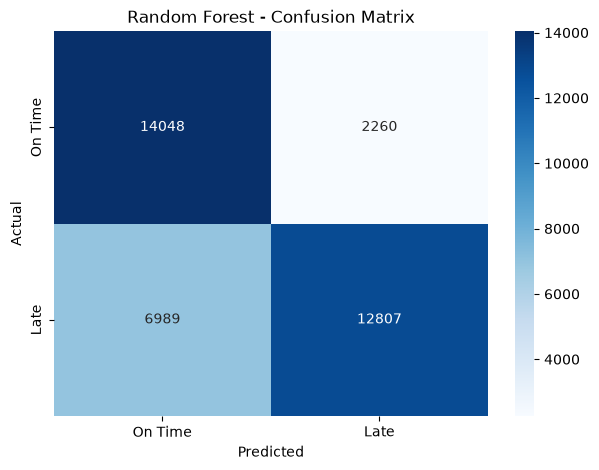

In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['On Time', 'Late'],
    yticklabels=['On Time', 'Late']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")

plt.show()

In [19]:
y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.844


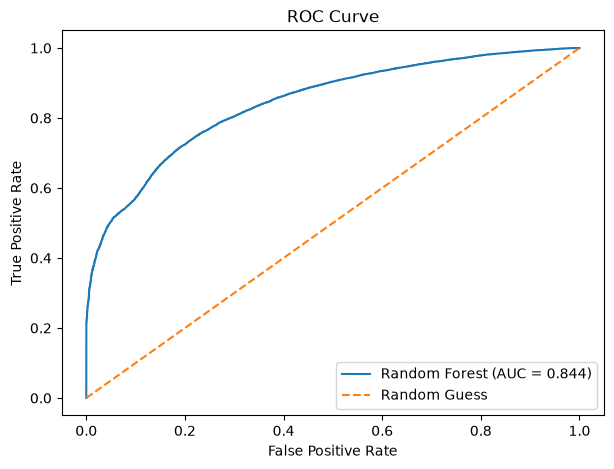

In [20]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("New training shape:", X_train_new.shape)
print("Validation shape:", X_val.shape)

New training shape: (115532, 21)
Validation shape: (28883, 21)


In [22]:
rf_tuning = clone(rf_pipeline)

rf_tuning.fit(X_train_new, y_train_new)

print("Validation model trained successfully!")

Validation model trained successfully!


In [23]:
y_val_prob = rf_tuning.predict_proba(X_val)[:, 1]

print("Validation probabilities generated!")

Validation probabilities generated!


In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Precision:", round(precision_score(y_val, y_val_pred), 3))
    print("Recall:", round(recall_score(y_val, y_val_pred), 3))
    print("F1 Score:", round(f1_score(y_val, y_val_pred), 3))


Threshold: 0.3
Precision: 0.593
Recall: 0.972
F1 Score: 0.737

Threshold: 0.35
Precision: 0.65
Recall: 0.917
F1 Score: 0.761

Threshold: 0.4
Precision: 0.726
Recall: 0.821
F1 Score: 0.77

Threshold: 0.45
Precision: 0.796
Recall: 0.71
F1 Score: 0.75

Threshold: 0.5
Precision: 0.833
Recall: 0.631
F1 Score: 0.718

Threshold: 0.55
Precision: 0.853
Recall: 0.584
F1 Score: 0.694

Threshold: 0.6
Precision: 0.867
Recall: 0.556
F1 Score: 0.678


In [25]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

best_threshold = 0.40

y_val_pred = (y_val_prob >= best_threshold).astype(int)

print("Validation Accuracy:",
      round(accuracy_score(y_val, y_val_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

Validation Accuracy: 73.17 %

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.62      0.68     13047
           1       0.73      0.82      0.77     15836

    accuracy                           0.73     28883
   macro avg       0.73      0.72      0.72     28883
weighted avg       0.73      0.73      0.73     28883


Confusion Matrix:
[[ 8137  4910]
 [ 2839 12997]]


In [26]:
rf_final = clone(rf_pipeline)

rf_final.fit(X_train, y_train)

print("Final Random Forest model trained successfully!")

Final Random Forest model trained successfully!


In [27]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

y_test_prob = rf_final.predict_proba(X_test)[:, 1]

y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("FINAL TEST PERFORMANCE")
print("-----------------------")
print("Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_test_pred) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, y_test_pred) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, y_test_pred) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

FINAL TEST PERFORMANCE
-----------------------
Threshold: 0.4
Accuracy: 75.31 %
Precision: 74.71 %
Recall: 83.11 %
F1 Score: 78.69 %

Confusion Matrix:
[[10738  5570]
 [ 3343 16453]]


In [28]:
def classify_delivery_risk(probability):

    if probability < 0.30:
        return "Low"

    elif probability < 0.60:
        return "Medium"

    else:
        return "High"

In [29]:
risk_probabilities = rf_final.predict_proba(X_test)[:, 1]

risk_categories = [
    classify_delivery_risk(prob)
    for prob in risk_probabilities
]

risk_results = pd.DataFrame({
    'Actual_Delivery_Status': y_test.values,
    'Late_Delivery_Probability': risk_probabilities,
    'Risk_Category': risk_categories
})

risk_results.head(10)

,Actual_Delivery_Status,Late_Delivery_Probability,Risk_Category
0,0,0.290535,Low
1,0,0.703761,High
2,0,0.174984,Low
3,0,0.291059,Low
4,1,0.468135,Medium
5,0,0.386273,Medium
6,1,0.355743,Medium
7,0,0.366953,Medium
8,1,0.839527,High
9,1,0.259016,Low


In [30]:
print(risk_results['Risk_Category'].value_counts())

print("\nRisk category percentage:")
print(
    risk_results['Risk_Category']
    .value_counts(normalize=True) * 100
)

Risk_Category
Medium    19052
High      12739
Low        4313
Name: count, dtype: int64

Risk category percentage:
Risk_Category
Medium    52.769776
High      35.284179
Low       11.946045
Name: proportion, dtype: float64


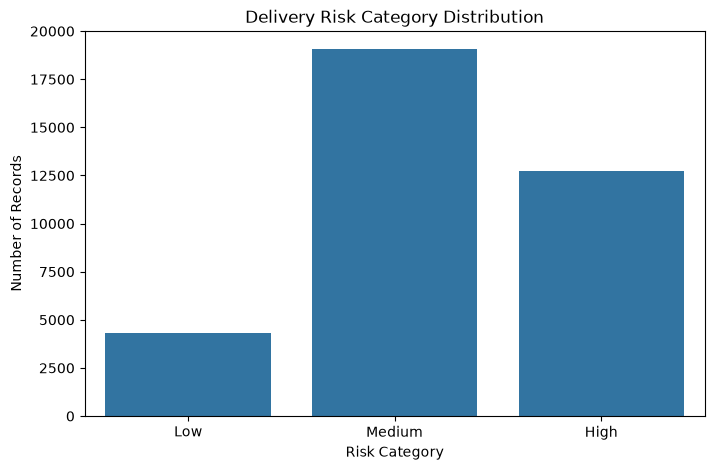

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=risk_results,
    x='Risk_Category',
    order=['Low', 'Medium', 'High']
)

plt.title('Delivery Risk Category Distribution')
plt.xlabel('Risk Category')
plt.ylabel('Number of Records')

plt.show()

In [32]:
import joblib
import os

os.makedirs('../models', exist_ok=True)

model_artifact = {
    'model': rf_final,
    'threshold': best_threshold,
    'risk_categories': {
        'Low': 'Below 0.30',
        'Medium': '0.30 to below 0.60',
        'High': '0.60 and above'
    }
}

joblib.dump(
    model_artifact,
    '../models/late_delivery_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [33]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Calculating feature importance...")

importance_result = permutation_importance(
    rf_final,
    X_test,
    y_test,
    n_repeats=3,
    random_state=42,
    scoring='f1',
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance_result.importances_mean
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(15))

Calculating feature importance...
                     Feature  Importance
0                       Type    0.038247
8                 Order City    0.035387
15               Order State    0.032230
6                  Longitude    0.023687
9              Order Country    0.021218
5                   Latitude    0.021070
14              Order Region    0.015002
3           Customer Segment    0.014893
7                     Market    0.012228
10       Order Item Discount    0.001666
11  Order Item Discount Rate    0.001446
2              Category Name    0.001417
4            Department Name    0.001343
19          Order_Complexity    0.000439
12  Order Item Product Price    0.000397


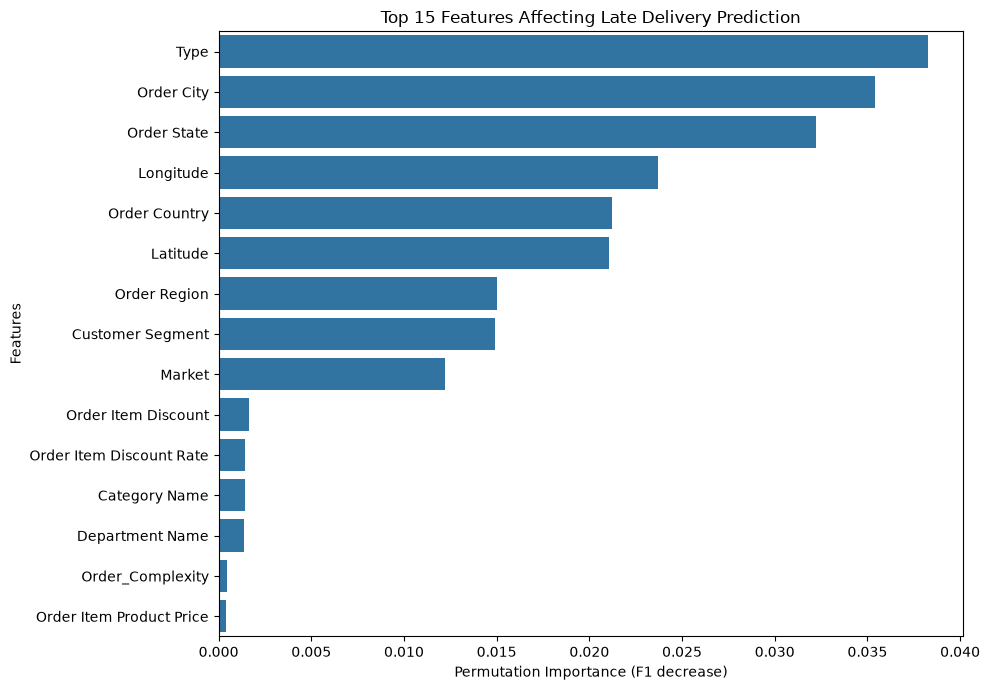

In [34]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Features Affecting Late Delivery Prediction')
plt.xlabel('Permutation Importance (F1 decrease)')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [35]:
import os

os.makedirs('../visuals', exist_ok=True)

feature_importance.to_csv(
    '../visuals/feature_importance.csv',
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


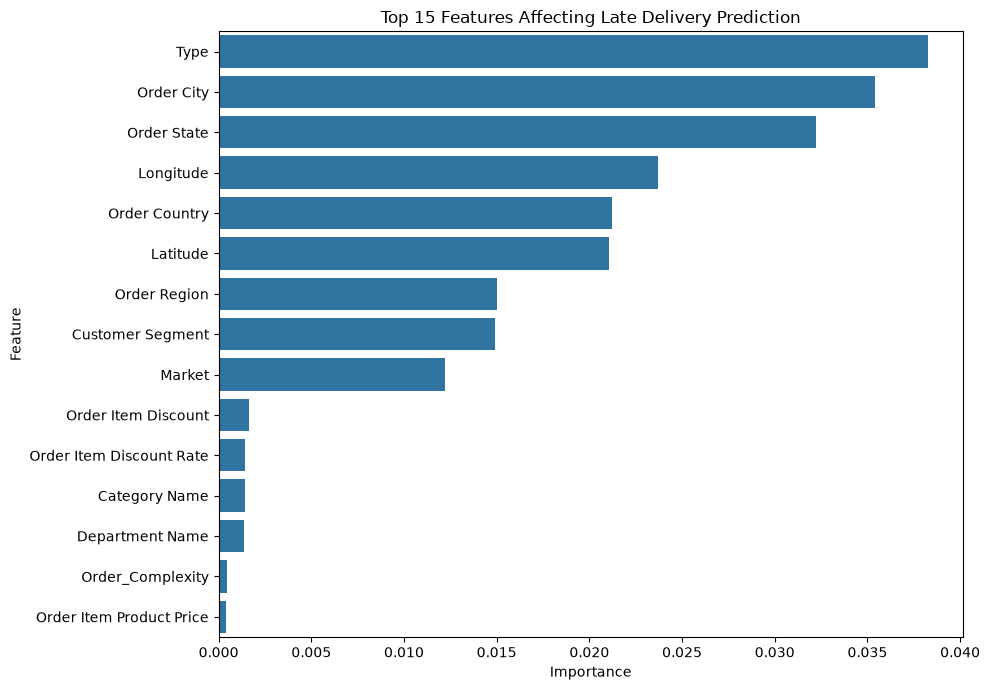

In [36]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Features Affecting Late Delivery Prediction')
plt.tight_layout()

plt.savefig(
    '../visuals/feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [37]:
import joblib
import os

os.makedirs('../models', exist_ok=True)

joblib.dump(
    {
        'model': rf_final,
        'threshold': best_threshold,
        'feature_columns': X_train.columns.tolist()
    },
    '../models/late_delivery_model.pkl'
)

print("Final model saved successfully!")

Final model saved successfully!


In [38]:
print("Order Type values:")
print(df['Type'].value_counts())

print("\nShipping Mode values:")
print(df['Shipping Mode'].value_counts())

print("\nScheduled shipping days:")
print(df['Days for shipment (scheduled)'].value_counts().sort_index())

Order Type values:
Type
DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Shipping Mode values:
Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64

Scheduled shipping days:
Days for shipment (scheduled)
0      9737
1     27814
2     35216
4    107752
Name: count, dtype: int64


In [39]:
import os

model_path = '../models/late_delivery_model.pkl'

if os.path.exists(model_path):
    print("Model file exists!")
    print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
else:
    print("Model file not found. Save the model first.")

Model file exists!
File size: 352986.82 KB


In [40]:
shipping_check = pd.crosstab(
    df['Shipping Mode'],
    df['Days for shipment (scheduled)']
)

print(shipping_check)

Days for shipment (scheduled)     0      1      2       4
Shipping Mode                                            
First Class                       0  27814      0       0
Same Day                       9737      0      0       0
Second Class                      0      0  35216       0
Standard Class                    0      0      0  107752


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Remove scheduled shipping days
X_train_reduced = X_train.drop(
    columns=['Days for shipment (scheduled)']
)

X_test_reduced = X_test.drop(
    columns=['Days for shipment (scheduled)']
)

print("New training shape:", X_train_reduced.shape)
print("New testing shape:", X_test_reduced.shape)

New training shape: (144415, 20)
New testing shape: (36104, 20)


In [42]:
from pandas.api.types import is_numeric_dtype

num_cols = [
    col for col in X_train_reduced.columns
    if is_numeric_dtype(X_train_reduced[col])
]

cat_cols = [
    col for col in X_train_reduced.columns
    if not is_numeric_dtype(X_train_reduced[col])
]

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Quantity', 'Product Price', 'Shipping_Pressure_Index']
Categorical: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Shipping Mode', 'Order_Complexity', 'Scheduled_Duration_Category']


In [43]:
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=50
    ))
])

preprocessor_reduced = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

In [44]:
rf_reduced = Pipeline(steps=[
    ('preprocessor', preprocessor_reduced),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ))
])

rf_reduced.fit(X_train_reduced, y_train)

print("Reduced model trained successfully!")

Reduced model trained successfully!


In [45]:
y_reduced_prob = rf_reduced.predict_proba(X_test_reduced)[:, 1]

y_reduced_pred = (
    y_reduced_prob >= 0.40
).astype(int)

print("MODEL WITHOUT SCHEDULED SHIPPING DAYS")
print("------------------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, y_reduced_pred) * 100, 2), "%")

print("Precision:",
      round(precision_score(y_test, y_reduced_pred) * 100, 2), "%")

print("Recall:",
      round(recall_score(y_test, y_reduced_pred) * 100, 2), "%")

print("F1 Score:",
      round(f1_score(y_test, y_reduced_pred) * 100, 2), "%")

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_reduced_prob), 4))

MODEL WITHOUT SCHEDULED SHIPPING DAYS
------------------------------------
Accuracy: 74.81 %
Precision: 74.15 %
Recall: 83.0 %
F1 Score: 78.32 %
ROC-AUC: 0.8405


In [46]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'Original Model': [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        roc_auc_score(y_test, y_test_prob)
    ],
    'Reduced Model': [
        accuracy_score(y_test, y_reduced_pred),
        precision_score(y_test, y_reduced_pred),
        recall_score(y_test, y_reduced_pred),
        f1_score(y_test, y_reduced_pred),
        roc_auc_score(y_test, y_reduced_prob)
    ]
})

print(comparison.round(4))

      Metric  Original Model  Reduced Model
0   Accuracy          0.7531         0.7481
1  Precision          0.7471         0.7415
2     Recall          0.8311         0.8300
3   F1 Score          0.7869         0.7832
4    ROC-AUC          0.8440         0.8405
